# Linear models comparison

Trains the 6 methods of `implementations.py` on the **same features and the same 80/20 split** as `baseline.ipynb`
(cleaning + one-hot + interactions), tunes each one on the validation set, compares them on F1,
and writes one AIcrowd submission per model in `submissions/`.

For the regression models (MSE GD / SGD, least squares, ridge) the target is y in {0, 1} and the prediction
is a score; for the logistic models it is a probability. In both cases a person is predicted sick when the score
is above a threshold, chosen to maximise F1 on the validation set.

In [1]:
import os
import csv
import time

import numpy as np
import matplotlib.pyplot as plt

from helpers import load_csv_data, create_csv_submission
from implementations import (mean_squared_error_gd, mean_squared_error_sgd, least_squares,
                             ridge_regression, logistic_regression, reg_logistic_regression)
from preprocessing import (compute_groups, clean, fit_column_filter, one_hot, add_interactions,
                           split_train_val, fit_preprocessing, apply_preprocessing, f1, sigmoid)

DATA_PATH = "data/dataset"
SUB_DIR = "submissions"

Matplotlib is building the font cache; this may take a moment.


## 1. Features (same pipeline as `baseline.ipynb`)

In [2]:
x_train, x_test, y_train, train_ids, test_ids = load_csv_data(DATA_PATH)
with open(os.path.join(DATA_PATH, "x_train.csv")) as f:
    names = next(csv.reader(f))[1:]
y01 = np.where(y_train == 1, 1, 0).astype(float)

# cleaning
groups = compute_groups(x_train, names)
x_tr, kept = clean(x_train, names, groups)
x_te, _ = clean(x_test, names, groups)
keep = fit_column_filter(x_tr)
x_tr, x_te = x_tr[:, keep], x_te[:, keep]
kept = [n for n, k in zip(kept, keep) if k]

# one-hot + interactions
CATEGORICAL = ["MARITAL", "EMPLOY1", "RENTHOM1", "PERSDOC2", "_RACE", "SXORIENT", "TRNSGNDR"]
INTERACTIONS = [("_AGE80", "BPHIGH4"), ("_AGE80", "DIABETE3"), ("_AGE80", "GENHLTH"),
                ("_AGE80", "SEX"), ("_AGE80", "CVDSTRK3"), ("GENHLTH", "DIFFWALK")]
SQUARES = ["_AGE80", "_BMI5"]
x_tr, x_te, kept = one_hot(x_tr, x_te, kept, CATEGORICAL)
x_tr, x_te, kept = add_interactions(x_tr, x_te, kept, INTERACTIONS, SQUARES)

# drop exact duplicate columns (e.g. _CRACE1 == _CPRACE): they make X^T X singular
_, first = np.unique(np.nan_to_num(x_tr, nan=-12345.678), axis=1, return_index=True)
first = np.sort(first)
print("Duplicate columns dropped:", [kept[i] for i in range(len(kept)) if i not in set(first)])
x_tr, x_te = x_tr[:, first], x_te[:, first]
kept = [kept[i] for i in first]
print("Features:", x_tr.shape[1])

Duplicate columns dropped: ['_CPRACE', '_DRDXAR1', '_TOTINDA', '_AIDTST3']
Features: 203


## 2. Train / validation split and standardization

In [3]:
i_tr, i_val = split_train_val(len(x_tr))
mean, std = fit_preprocessing(x_tr[i_tr])
X_tr = apply_preprocessing(x_tr[i_tr], mean, std)    # with bias column
X_val = apply_preprocessing(x_tr[i_val], mean, std)
y_tr, y_val = y01[i_tr], y01[i_val]

# largest eigenvalue of X^T X / N -> safe step size for gradient descent on the MSE (gamma < 2 / L)
eig = np.linalg.eigvalsh(X_tr.T @ X_tr / len(y_tr))
L = eig[-1]
print(f"Train {X_tr.shape}, validation {X_val.shape}")
print(f"Eigenvalues of X^T X / N: min = {eig[0]:.1e}, max = {L:.2f}")
print("min eigenvalue ~ 0 -> some features are exact linear combinations of others "
      "(e.g. TOLDHI2 / _RFCHOL): plain least squares is ill-posed, ridge fixes it.")

Train (262508, 204), validation (65627, 204)
Eigenvalues of X^T X / N: min = -5.9e-15, max = 13.87
min eigenvalue ~ 0 -> some features are exact linear combinations of others (e.g. TOLDHI2 / _RFCHOL): plain least squares is ill-posed, ridge fixes it.


## 3. Evaluation helpers

In [4]:
def best_threshold(y_true, scores):
    """Threshold on the scores that maximises F1 (candidates = score quantiles, works for any scale)."""
    best_t, best_f = 0.0, -1.0
    for t in np.quantile(scores, np.linspace(0.50, 0.995, 100)):
        f = f1(y_true, (scores >= t).astype(int))
        if f > best_f:
            best_t, best_f = t, f
    return best_t, best_f


def metrics(y_true, scores, t):
    y_pred = (scores >= t).astype(int)
    tp = np.sum((y_pred == 1) & (y_true == 1))
    return {
        "f1": f1(y_true, y_pred),
        "accuracy": np.mean(y_pred == y_true),
        "precision": tp / max(np.sum(y_pred == 1), 1),
        "recall": tp / np.sum(y_true == 1),
    }


def score_fn(name):
    """Logistic models output probabilities, regression models output raw scores."""
    return (lambda X, w: sigmoid(X @ w)) if "logistic" in name else (lambda X, w: X @ w)


results = {}   # model name -> dict with hyperparameters, threshold and validation metrics


def record(name, w, params, seconds):
    scores = score_fn(name)(X_val, w)
    t, _ = best_threshold(y_val, scores)
    m = metrics(y_val, scores, t)
    results[name] = {"params": params, "threshold": t, "w": w, **m}
    print(f"{name:<22} F1 = {m['f1']:.4f}  acc = {m['accuracy']:.3f}  "
          f"precision = {m['precision']:.3f}  recall = {m['recall']:.3f}  "
          f"threshold = {t:.3f}  {params}  ({seconds:.1f}s)")

## 4. Train the 6 models
Hyperparameters with several values are tuned on the validation F1; the best one is kept.

In [5]:
D = X_tr.shape[1]

# 1. Linear regression with gradient descent (step 1/L is always stable)
t0 = time.time()
gamma = 1.0 / L
w, _ = mean_squared_error_gd(y_tr, X_tr, np.zeros(D), 1000, gamma)
record("mse_gd", w, {"gamma": round(gamma, 4), "max_iters": 1000}, time.time() - t0)

# 2. Linear regression with SGD (batch size 1). One extreme row can make big steps explode,
#    so gamma must be small; 2 epochs over the training set.
t0 = time.time()
np.random.seed(0)
w, _ = mean_squared_error_sgd(y_tr, X_tr, np.zeros(D), 2 * len(y_tr), 1e-5)
record("mse_sgd", w, {"gamma": 1e-5, "max_iters": 2 * len(y_tr)}, time.time() - t0)

# 3. Least squares (normal equations). X^T X is singular here, see section 2.
t0 = time.time()
w, _ = least_squares(y_tr, X_tr)
record("least_squares", w, {}, time.time() - t0)
print(f"   max |w| = {np.abs(w).max():.1f}  (huge weights = sign of the singular system)")

mse_gd                 F1 = 0.4231  acc = 0.859  precision = 0.333  recall = 0.581  threshold = 0.206  {'gamma': np.float64(0.0721), 'max_iters': 1000}  (39.3s)


mse_sgd                F1 = 0.4167  acc = 0.849  precision = 0.317  recall = 0.607  threshold = 0.194  {'gamma': 1e-05, 'max_iters': 525016}  (1.6s)


least_squares          F1 = 0.4245  acc = 0.865  precision = 0.342  recall = 0.559  threshold = 0.215  {}  (0.5s)
   max |w| = 152.4  (huge weights = sign of the singular system)


In [6]:
# 4. Ridge regression: tune lambda
print("Ridge, lambda search:")
best = None
for lam in [1e-8, 1e-6, 1e-5, 1e-4, 1e-3, 1e-2, 1e-1]:
    w, _ = ridge_regression(y_tr, X_tr, lam)
    t, f = best_threshold(y_val, X_val @ w)
    print(f"   lambda = {lam:.0e}  F1 = {f:.4f}")
    if best is None or f > best[0]:
        best = (f, lam, w)
t0 = time.time()
record("ridge_regression", best[2], {"lambda_": best[1]}, time.time() - t0)

Ridge, lambda search:


   lambda = 1e-08  F1 = 0.4245


   lambda = 1e-06  F1 = 0.4245


   lambda = 1e-05  F1 = 0.4242


   lambda = 1e-04  F1 = 0.4246


   lambda = 1e-03  F1 = 0.4240


   lambda = 1e-02  F1 = 0.4220


   lambda = 1e-01  F1 = 0.4181
ridge_regression       F1 = 0.4246  acc = 0.865  precision = 0.342  recall = 0.559  threshold = 0.215  {'lambda_': 0.0001}  (0.0s)


In [7]:
# 5. Logistic regression (gradient descent). gamma = 0.5 is stable here
#    (the logistic loss is (L/4)-smooth, so any gamma < 8/L works).
t0 = time.time()
w, _ = logistic_regression(y_tr, X_tr, np.zeros(D), 1000, 0.5)
record("logistic_regression", w, {"gamma": 0.5, "max_iters": 1000}, time.time() - t0)

logistic_regression    F1 = 0.4284  acc = 0.875  precision = 0.361  recall = 0.528  threshold = 0.205  {'gamma': 0.5, 'max_iters': 1000}  (31.7s)


In [8]:
# 6. Regularized logistic regression: tune lambda
print("Regularized logistic, lambda search:")
best = None
for lam in [1e-6, 1e-5, 1e-4, 1e-3, 1e-2]:
    w, _ = reg_logistic_regression(y_tr, X_tr, lam, np.zeros(D), 1000, 0.5)
    t, f = best_threshold(y_val, sigmoid(X_val @ w))
    print(f"   lambda = {lam:.0e}  F1 = {f:.4f}")
    if best is None or f > best[0]:
        best = (f, lam, w)
t0 = time.time()
record("reg_logistic_regression", best[2],
       {"lambda_": best[1], "gamma": 0.5, "max_iters": 1000}, time.time() - t0)

Regularized logistic, lambda search:


   lambda = 1e-06  F1 = 0.4284


   lambda = 1e-05  F1 = 0.4284


   lambda = 1e-04  F1 = 0.4287


   lambda = 1e-03  F1 = 0.4280


   lambda = 1e-02  F1 = 0.4263
reg_logistic_regression F1 = 0.4287  acc = 0.875  precision = 0.361  recall = 0.528  threshold = 0.206  {'lambda_': 0.0001, 'gamma': 0.5, 'max_iters': 1000}  (0.0s)


## 5. Comparison

model                        F1    acc   prec recall
reg_logistic_regression  0.4287 0.875 0.361 0.528
logistic_regression      0.4284 0.875 0.361 0.528
ridge_regression         0.4246 0.865 0.342 0.559
least_squares            0.4245 0.865 0.342 0.559
mse_gd                   0.4231 0.859 0.333 0.581
mse_sgd                  0.4167 0.849 0.317 0.607


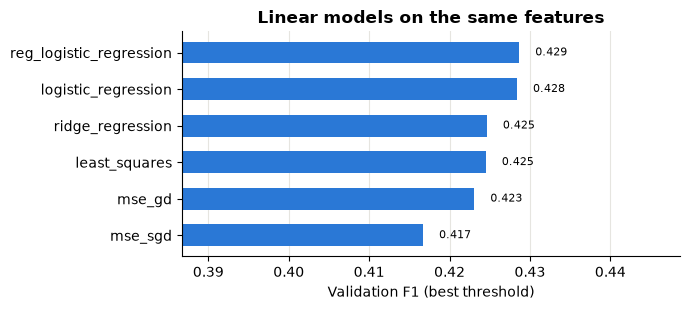

In [9]:
order = sorted(results, key=lambda n: results[n]["f1"], reverse=True)
print(f"{'model':<24} {'F1':>6} {'acc':>6} {'prec':>6} {'recall':>6}")
for n in order:
    r = results[n]
    print(f"{n:<24} {r['f1']:.4f} {r['accuracy']:.3f} {r['precision']:.3f} {r['recall']:.3f}")

fig, ax = plt.subplots(figsize=(7, 3.2))
vals = [results[n]["f1"] for n in order][::-1]
ax.barh(order[::-1], vals, color="#2a78d6", height=0.6)
for i, v in enumerate(vals):
    ax.text(v + 0.002, i, f"{v:.3f}", va="center", fontsize=8)
ax.set_xlim(min(vals) - 0.03, max(vals) + 0.02)
ax.set_xlabel("Validation F1 (best threshold)")
ax.set_title("Linear models on the same features", fontweight="bold")
ax.spines[["top", "right"]].set_visible(False)
ax.grid(axis="x", color="#e6e5e0")
ax.set_axisbelow(True)
plt.tight_layout()
plt.show()

## 6. Submissions

Each model is retrained on **all** training data (train + validation) with its chosen hyperparameters,
then the validation threshold is applied to the test set. One file per model in `submissions/`.

In [10]:
os.makedirs(SUB_DIR, exist_ok=True)
mean_all, std_all = fit_preprocessing(x_tr)
X_all = apply_preprocessing(x_tr, mean_all, std_all)
X_test = apply_preprocessing(x_te, mean_all, std_all)
D = X_all.shape[1]


def retrain(name, p):
    if name == "mse_gd":
        return mean_squared_error_gd(y01, X_all, np.zeros(D), p["max_iters"], p["gamma"])[0]
    if name == "mse_sgd":
        np.random.seed(0)
        return mean_squared_error_sgd(y01, X_all, np.zeros(D), 2 * len(y01), p["gamma"])[0]
    if name == "least_squares":
        return least_squares(y01, X_all)[0]
    if name == "ridge_regression":
        return ridge_regression(y01, X_all, p["lambda_"])[0]
    if name == "logistic_regression":
        return logistic_regression(y01, X_all, np.zeros(D), p["max_iters"], p["gamma"])[0]
    if name == "reg_logistic_regression":
        return reg_logistic_regression(y01, X_all, p["lambda_"], np.zeros(D), p["max_iters"], p["gamma"])[0]


for name in order:
    r = results[name]
    w = retrain(name, r["params"])
    scores = score_fn(name)(X_test, w)
    y_pred = np.where(scores >= r["threshold"], 1, -1)
    path = os.path.join(SUB_DIR, f"submission_{name}.csv")
    create_csv_submission(test_ids, y_pred, path)
    print(f"{path:<48} val F1 = {r['f1']:.4f}   predicted positives in test = {np.mean(y_pred == 1):.1%}")

submissions/submission_reg_logistic_regression.csv val F1 = 0.4287   predicted positives in test = 13.2%


submissions/submission_logistic_regression.csv   val F1 = 0.4284   predicted positives in test = 13.2%


submissions/submission_ridge_regression.csv      val F1 = 0.4246   predicted positives in test = 14.7%


submissions/submission_least_squares.csv         val F1 = 0.4245   predicted positives in test = 14.7%


submissions/submission_mse_gd.csv                val F1 = 0.4231   predicted positives in test = 15.7%


submissions/submission_mse_sgd.csv               val F1 = 0.4167   predicted positives in test = 16.4%
